# Part II - Ford GoBike Trip Duration by User Type and Day
## by Siddhant Maksare)

## Investigation Overview
This presentation examines how Ford GoBike trip duration varies according to the day of the week and user type. The main goal is to explain the differences between subscriber and customer riding patterns and determine whether these patterns change between weekdays and weekends.

## Dataset Overview and Executive Summary
The dataset contains 183,412 Ford GoBike trips recorded in the San Francisco Bay Area during February 2019. Each record represents an individual trip and includes information about trip duration, start and end times, station locations, user type, and selected rider characteristics.

The explanatory analysis focuses on how trip duration and usage patterns differ by day of the week and between subscribers and customers.


## Key Insights & Findings

- Most Ford GoBike trips were short, with a median duration of approximately 8.6 minutes.

- Bike usage was considerably higher on weekdays than on weekends, suggesting that many trips were related to commuting or other routine travel.

- Subscribers generally took short trips, with median durations close to eight minutes on both weekdays and weekends.

- Customers took longer trips than subscribers, especially on weekends. Their median trip duration increased from approximately 12.4 minutes on weekdays to 16.1 minutes on weekends.

- Approximately 21.2% of weekend customer trips lasted longer than 30 minutes, compared with only 4.8% of weekend subscriber trips.

- The longer overall trip durations observed on weekends were primarily associated with customer activity, suggesting more recreational use among customers.

In [1]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
bikes = pd.read_csv("Downloads/201902-fordgobike-tripdata.csv")
bikes.head()

,duration_sec,start_time,end_time,start_station_id,start_station_name,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_latitude,end_station_longitude,bike_id,user_type,member_birth_year,member_gender,bike_share_for_all_trip
0,52185,2019-02-28 17:32:10.1450,2019-03-01 08:01:55.9750,21.0,Montgomery St BART Station (Market St at 2nd St),37.789625,-122.400811,13.0,Commercial St at Montgomery St,37.794231,-122.402923,4902,Customer,1984.0,Male,No
1,42521,2019-02-28 18:53:21.7890,2019-03-01 06:42:03.0560,23.0,The Embarcadero at Steuart St,37.791464,-122.391034,81.0,Berry St at 4th St,37.775880,-122.393170,2535,Customer,NaN,NaN,No
2,61854,2019-02-28 12:13:13.2180,2019-03-01 05:24:08.1460,86.0,Market St at Dolores St,37.769305,-122.426826,3.0,Powell St BART Station (Market St at 4th St),37.786375,-122.404904,5905,Customer,1972.0,Male,No
3,36490,2019-02-28 17:54:26.0100,2019-03-01 04:02:36.8420,375.0,Grove St at Masonic Ave,37.774836,-122.446546,70.0,Central Ave at Fell St,37.773311,-122.444293,6638,Subscriber,1989.0,Other,No
4,1585,2019-02-28 23:54:18.5490,2019-03-01 00:20:44.0740,7.0,Frank H Ogawa Plaza,37.804562,-122.271738,222.0,10th Ave at E 15th St,37.792714,-122.248780,4898,Subscriber,1974.0,Male,Yes


In [3]:
#Data Preparation 

#convert timestamps 
bikes["start_time"] = pd.to_datetime(bikes["start_time"])
bikes["end_time"] = pd.to_datetime(bikes["end_time"])

#Create useful variables
bikes["duration_min"] = bikes["duration_sec"] / 60
bikes["start_hour"] = bikes["start_time"].dt.hour
bikes["start_day"] = bikes["start_time"].dt.day_name()

day_order = [ "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
bikes.shape

(183412, 19)

### Visualization 1 Number of trips by day of the week
This bar chart shows the total number of Ford GoBike trips that started on each day of the week. The days are arranged chronologically from Monday to Sunday. Weekdays and weekends use different colors to make the usage pattern easier to recognize.

The chart shows that bike usage was considerably higher on weekdays. Thursday recorded the most trips, with 35,197 rides, while Saturday and Sunday recorded approximately 15,000 trips each. This pattern suggests that many riders used Ford GoBike for commuting or other routine weekday travel.

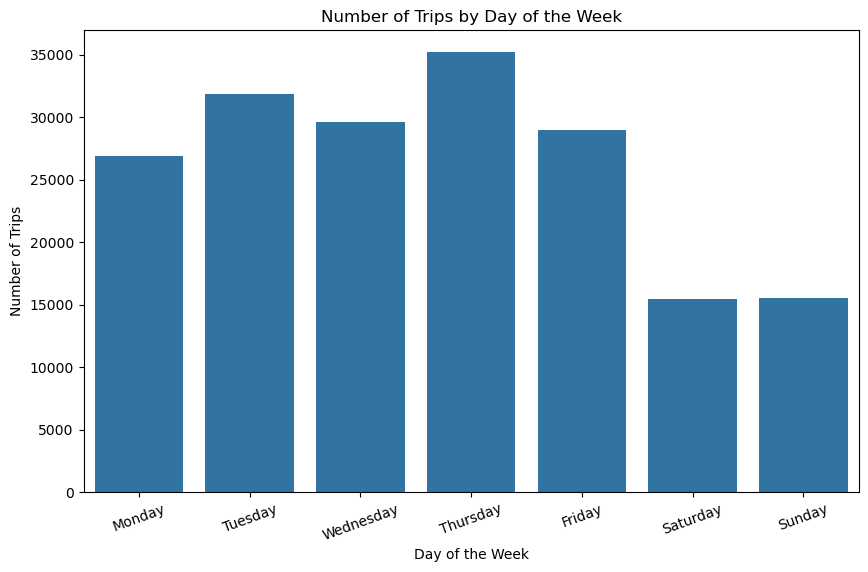

In [4]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(data=bikes,
                  x="start_day", 
                  order=day_order)

plt.title("Number of Trips by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Trips")
plt.xticks(rotation=20)
plt.show()

### Visualization 2 Trip duration over time: scatter plot

This scatter plot shows how trip duration varied throughout February 2019. The trip start date appears on the x-axis, while trip duration in minutes appears on the y-axis. A logarithmic scale is used for trip duration so that both common short trips and unusually long trips can be displayed clearly.

Most trips remained short throughout the month, while a small number of longer trips appeared on different dates. There was no clear upward or downward trend in trip duration over time. The long-duration trips were scattered across the month rather than concentrated within a specific period, suggesting that they were isolated cases rather than part of a broader time-based pattern.

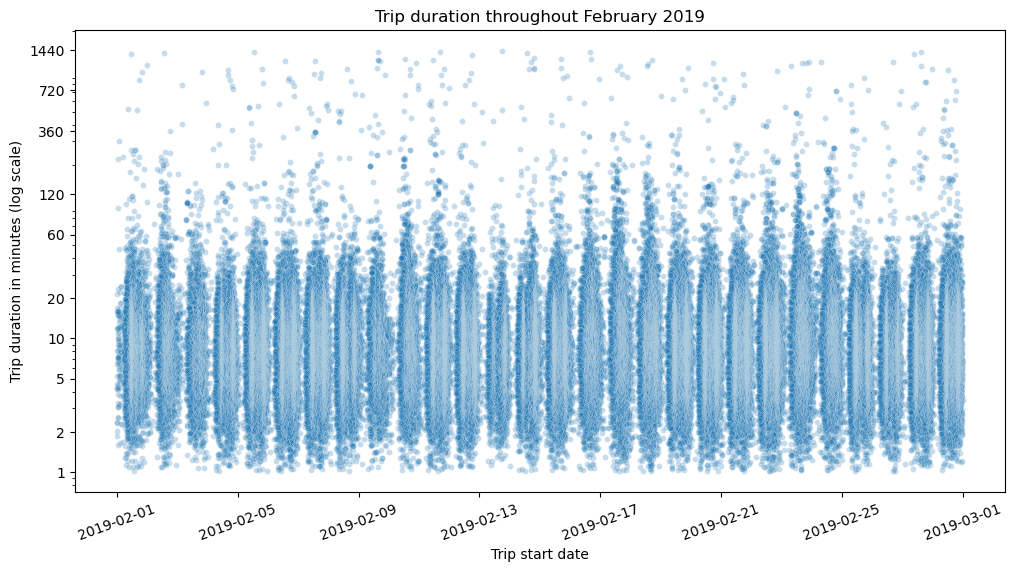

In [5]:
#Visualization 
plot_sample = bikes.sample(5000, random_state=42)

plt.figure(figsize=(12, 6))

sns.scatterplot(data=bikes, 
               x="start_time", 
               y="duration_min", 
               alpha=0.25,
               s=18)

plt.yscale("log")
plt.title("Trip duration throughout February 2019")
plt.xlabel("Trip start date")
plt.ylabel("Trip duration in minutes (log scale)")
plt.xticks(rotation=20)
ticks = [1, 2, 5, 10, 20, 60, 120, 360, 720, 1440]
plt.yticks(ticks, ticks)
plt.show()

### Visualization 3 Duration distribution by user type and day type: facet plot

This facet plot compares trip-duration distributions for customers and subscribers on weekdays and weekends. Each panel represents a different combination of user type and day type, allowing the shape and spread of the distributions to be compared directly.

Subscriber trips were concentrated around shorter durations and changed very little between weekdays and weekends. Customer trips had a wider distribution and were generally longer than subscriber trips. The difference was especially noticeable on weekends, when customer trips shifted toward longer durations. This indicates that subscribers used Ford GoBike consistently for short, routine journeys, while customers were more likely to take longer recreational trips on weekends.

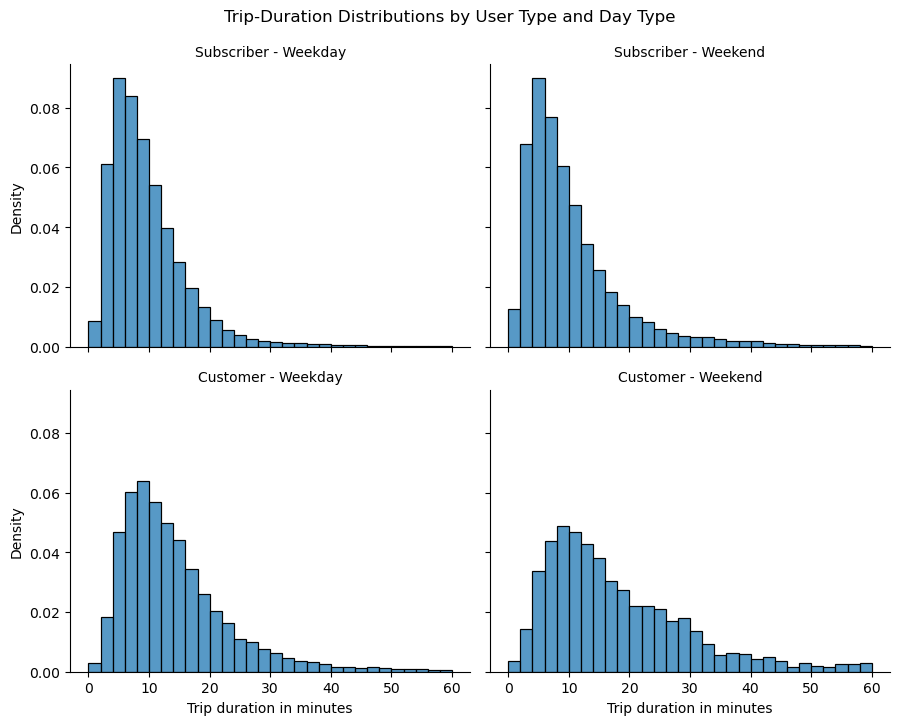

In [6]:
#Data Preparation 
bikes["day_type"] = np.where(bikes["start_time"].dt.dayofweek < 5, "Weekday", "Weekend")

bikes["day_type"] = pd.Categorical(bikes["day_type"], categories=["Weekday", "Weekend"], ordered=True)


#Visualization Facet plot.

#We will change the displayed range to be focused on trips duration of 60minutes or less so the main distribution remain visible. 
duration_view = bikes[bikes["duration_min"] <=60]

g = sns.displot(
    data=duration_view, 
    x="duration_min",
    row="user_type",
    col="day_type",
    bins = np.arange(0, 62, 2),
    stat="density",
    common_norm=False,
    height=3.5, 
    aspect=1.3
)

g.set_axis_labels("Trip duration in minutes", "Density")
g.set_titles("{row_name} - {col_name}")
g.figure.suptitle("Trip-Duration Distributions by User Type and Day Type", y=1.03)
plt.show()